In [ ]:
from tqdm import tqdm

import numpy as np

import matplotlib.pyplot as plt
import scipy.stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset



import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
from config import *


In [3]:
convert_i_to_x = False
save_plots = False
mean_marker_size= 1
titles=True

In [4]:
def get_trajectory(graph,popsize,d,repeat):
    output_name = f"CC-N-{popsize}-geom-{graph}-d-{d}-r-{r}-tr-{0}-repeat-{repeat}"
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
        
    dist_data_lines = []
    for line in lines:
        if line.strip() and line[:len("Na")]=="Na" and line[:len("Nav")]!="Nav":
            dist_data_lines.append(line.replace('\t',''))
    dist_data = [[subline.strip().split(' ')[1] for subline in line.strip().split(',')][0] for line in dist_data_lines ]
    
    traj = [float(x)/single_N for x in dist_data]
    if convert_i_to_x:
        traj = [i/popsize for i in traj]
    if len(traj)==0:
        return []
    if traj[-1]==0:
        return []
    else:
        return traj
    
def get_nav_trajectory(graph,popsize,d,repeat):
    output_name = f"CC-N-{popsize}-geom-{graph}-d-{d}-r-{r}-tr-{0}-repeat-{repeat}"
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
        
    dist_data = []
    for line in lines:
        if line.strip() and line[:len("Nav ")]=="Nav ":
            line = line.replace('\t','').replace('\n','')
            if len(line.strip().split(' ')) == 2:
                dist_data.append(line.strip().split(' ')[1])
    # print(dist_data)
    # dist_data = [[subline.strip().split(' ')[1] for subline in line.strip().split(',')][0] for line in dist_data_lines ]
    # print(dist_data)
    traj = [float(x) for x in dist_data]
    # print(traj)
    if len(traj)==0 or traj[-1]==0:
        return []
    else:
        return traj
    
def get_time_trajectory(graph,popsize,d,repeat):
    output_name = f"CC-N-{popsize}-geom-{graph}-d-{d}-r-{r}-tr-{0}-repeat-{repeat}"
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
        
    dist_data_lines = []
    for line in lines:
        if line.strip() and line[:len("Time")]=="Time":
            dist_data_lines.append(line.replace('\t',''))
    dist_data = [[subline.strip().split(' ')[1] for subline in line.strip().split(',')][0] for line in dist_data_lines ]
    
    traj = [float(x) for x in dist_data]
    if len(traj)==0 or traj[-1]==0:
        return []
    else:
        return traj
    
def get_stats(traj):
    mean = np.mean(traj)
    std = np.std(traj)
    n = len(traj)
    alpha = 0.05
    z = 1.96
    ci_mean_lower = mean - z * std / np.sqrt(n)
    ci_mean_upper = mean + z * std / np.sqrt(n)

    df = (n - 1)
    chi2_lower = scipy.stats.chi2.ppf(1 - alpha/2, df)
    chi2_upper = scipy.stats.chi2.ppf(alpha/2, df)
    sample_var = std ** 2
    ci_var_lower = (df * sample_var) / chi2_lower
    ci_var_upper = (df * sample_var) / chi2_upper

    return {"mean":mean,"std":std,"ci":(ci_mean_lower,ci_mean_upper),"ci_var":(ci_var_lower,ci_var_upper)}



In [22]:

graph_type = "Well-mixed"
# graph_type = "Regular"

In [23]:
single_N=1000
prop = 1/250

In [24]:
repeats = 100
actual_end = 10000

graphs = [{"code":f"r8","name":"Regular 8-degree"}, {"code":f"r4","name":"Regular 4-degree"}]
all_reg_trajectories = {}
all_reg_nav_trajectories = {}
for graph in graphs:

    trajectories = []
    nav_trajectories = []
    time_trajectories = []
    for repeat in tqdm(range(repeats)):
        try:
            traj = []
            traj += get_trajectory(graph['code'],single_N,single_d,repeat)
            while len(traj)<actual_end:
                traj.append(traj[-1])
            if traj[-1]==0 or all(np.array(traj[2:])==0.001):
                continue
            trajectories.append(traj)
            if graph_type=="Regular":
                nav_traj = get_nav_trajectory(graph['code'],single_N,single_d,repeat)
                while len(nav_traj)<actual_end:
                    nav_traj.append(nav_traj[-1])
                if len(nav_traj)>0:
                    nav_trajectories.append(nav_traj)
            time_traj = get_time_trajectory(graph['code'],single_N,single_d,repeat)
            time_trajectories.append(time_traj)
        except FileNotFoundError as e:
            print(f"No file for graph {graph['code']},N={single_N},d={single_d},repeat={repeat}")
            print(e)
            pass
        except IndexError as e:
            print(f"Index error for graph {graph['code']},N={single_N},d={single_d},repeat={repeat}")
            pass
    all_reg_trajectories[graph['name']] = trajectories
    all_reg_nav_trajectories[graph['name']] = nav_trajectories

100%|██████████| 100/100 [00:03<00:00, 31.48it/s]


In [9]:
total_edges = single_N*ks[0]*2
qav_trajectories=[]
for nav_traj,traj in zip(nav_trajectories,trajectories):
    qav_trajectories.append([nav/total_edges/x for nav,x in zip(nav_traj,traj)])


In [11]:
repeats = 500
actual_end = 10000
prop = 1/25
timestop_for_plotting = 15


all_trajectories = {}

graphs = [{"code":f"M","name":"Well-mixed"}]

for single_N in [50,100]:
# if True:
    for graph in graphs:
        wm_trajectories = []
        wm_time_trajectories = []
        for repeat in tqdm(range(repeats)):
            try:
                traj = [prop]
                traj += get_trajectory(graph['code'],single_N,single_d,repeat)
                while len(traj)<actual_end:
                    traj.append(traj[-1])
                if traj[-1]==0 or all(np.array(traj[2:])==0.001):
                    continue
                wm_trajectories.append(traj)
                time_traj = get_time_trajectory(graph['code'],single_N,single_d,repeat)
                wm_time_trajectories.append([0]+time_traj)
            except FileNotFoundError as e:
                # print(f"No file for graph {graph['code']},N={single_N},d={single_d},repeat={repeat}")
                print(e)
                pass
        all_trajectories[single_N] = wm_trajectories
      

100%|██████████| 500/500 [00:06<00:00, 81.94it/s]


{'code': 'M', 'name': 'Well-mixed'} 100 0.0399999999999995
0.04
{'code': 'M', 'name': 'Well-mixed'} 50 0.0399999999999995


/var/folders/x8/t754zhz129jg7vydskwt7htm0000gq/T/ipykernel_54841/4090424518.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


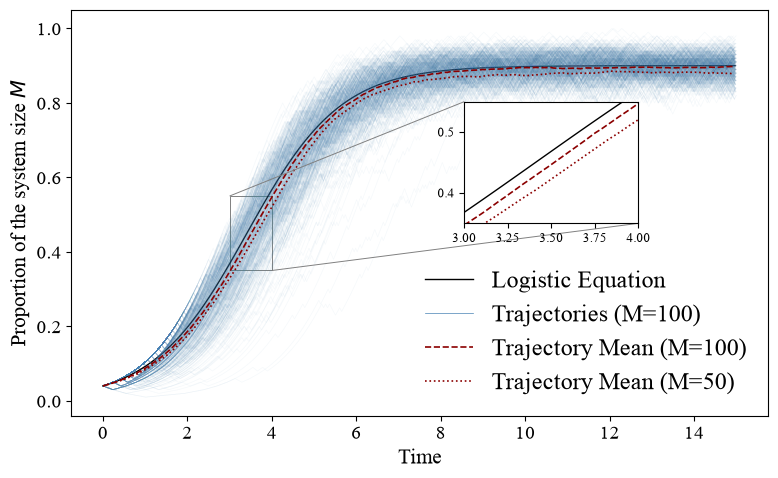

In [12]:
save_fig = True
timestop_for_plotting = 15
f1 = plt.figure(1, figsize=(8, 5))
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.linewidth": 0.8
})

ax_main = plt.gca()

ax_inset = inset_axes(ax_main, width="100%", height="100%",
                              bbox_to_anchor=(0.55, 0.45, 0.25, 0.3),
                              bbox_transform=ax_main.transAxes, loc='lower left')

# for single_N, linestyle in zip([1000], ['--', ':']):
for single_N, linestyle in zip([100,50], ['--', ':']):

    for graph in graphs:
        trajectories = np.array(all_trajectories[single_N])
        traj_mean = np.mean(trajectories, axis=0)
        print(graph, single_N, traj_mean[0])
        times = [0]
        for pa in traj_mean[:-1]:
            times.append(times[-1] + 1 / (single_N * pa * ((1 - pa) + single_d)))
        times = [t for t in times if t <= timestop_for_plotting]
        if single_N == 100:
            multiplier = 1
            x0 = np.mean(trajectories[:, 0])
            # x0 = 0.04
            print(x0)
            K = 1 - single_d
            growth = 1 - single_d
            dt = 0.01
            x_vals, t_vals = [], []
            t = 0
            p_nought_k_nought_term = (x0) / (K - x0)
            while t < max(times):
                x_vals.append((p_nought_k_nought_term * K * np.exp(growth * t)) / (1 + p_nought_k_nought_term * np.exp(growth * t)))
                t_vals.append(t)
                t += dt
            ax_main.plot(np.array(t_vals) * multiplier, x_vals, color='black', linewidth=1.0, label='Logistic Equation')
            ax_inset.plot(np.array(t_vals) * multiplier, x_vals, color='black', linewidth=1.0)
            label=True
            for traj in trajectories:
                if traj[-1]==0.001:
                    print(traj)
                    continue
                # temp_traj = np.array(traj[:timestop_for_plotting])
                times = [0]
                for pa in traj[:-1]:
                    times.append(times[-1] + 1/(single_N*pa*((1-pa)+single_d)))
                times = [t for t in times if t<=timestop_for_plotting]
                temp_traj = traj[:len(times)]
                # times = time_traj[:timestop_for_plotting]
                if label:
                    ax_main.plot(times, temp_traj, color='steelblue', alpha=0.05, linewidth=0.5,label="Trajectories (M={})".format(single_N))
                    
                    label=False
                else:
                    ax_main.plot(times, temp_traj, color='steelblue', alpha=0.05, linewidth=0.5)
        times = [0]
        for pa in traj_mean[:-1]:
            times.append(times[-1] + 1 / (single_N * pa * ((1 - pa) + single_d)))
        times = [t for t in times if t <= timestop_for_plotting]
        traj_mean = traj_mean[:len(times)]
        ax_main.plot(times, traj_mean, color='darkred', linestyle=linestyle, linewidth=1.2, label='Trajectory Mean (M={})'.format(single_N))
        ax_inset.plot(times, traj_mean, color='darkred', linestyle=linestyle, linewidth=1.2)

ax_main.set_xlabel("Time", fontsize=15)
ax_main.set_ylabel("Proportion of the system size $M$", fontsize=15)
leg = ax_main.legend(frameon=False, fontsize=17)

for lh in leg.legend_handles:
    lh.set_alpha(1)


ax_main.grid(False)


ax_inset.set_xlim(3, 4)
ax_inset.set_ylim(0.35, 0.55)
ax_inset.tick_params(labelsize=9)
ax_inset.grid(False)

mark_inset(ax_main, ax_inset, loc1=2, loc2=4, fc="none", ec="gray", lw=0.7, linestyle="-")

plt.tight_layout()

plt.savefig("trajectory_from_1.pdf", bbox_inches='tight')



In [13]:
single_N = 1000
proportion = 1/250

In [14]:
graphs = [{"code":f"r8","name":"Regular 8-degree"}, {"code":f"r4","name":"Regular 4-degree"}]


In [15]:
total_edges = single_N*ks[0]*2
all_reg_qav_trajectories = {}
for graph in graphs:
    all_reg_qav_trajectories[graph['name']] = []
    for nav_traj,traj in zip(all_reg_nav_trajectories[graph['name']],all_reg_trajectories[graph['name']]):
        all_reg_qav_trajectories[graph['name']].append([nav/(single_N*x*int(graph['code'][1:])*2) for nav,x in zip(nav_traj,traj)])

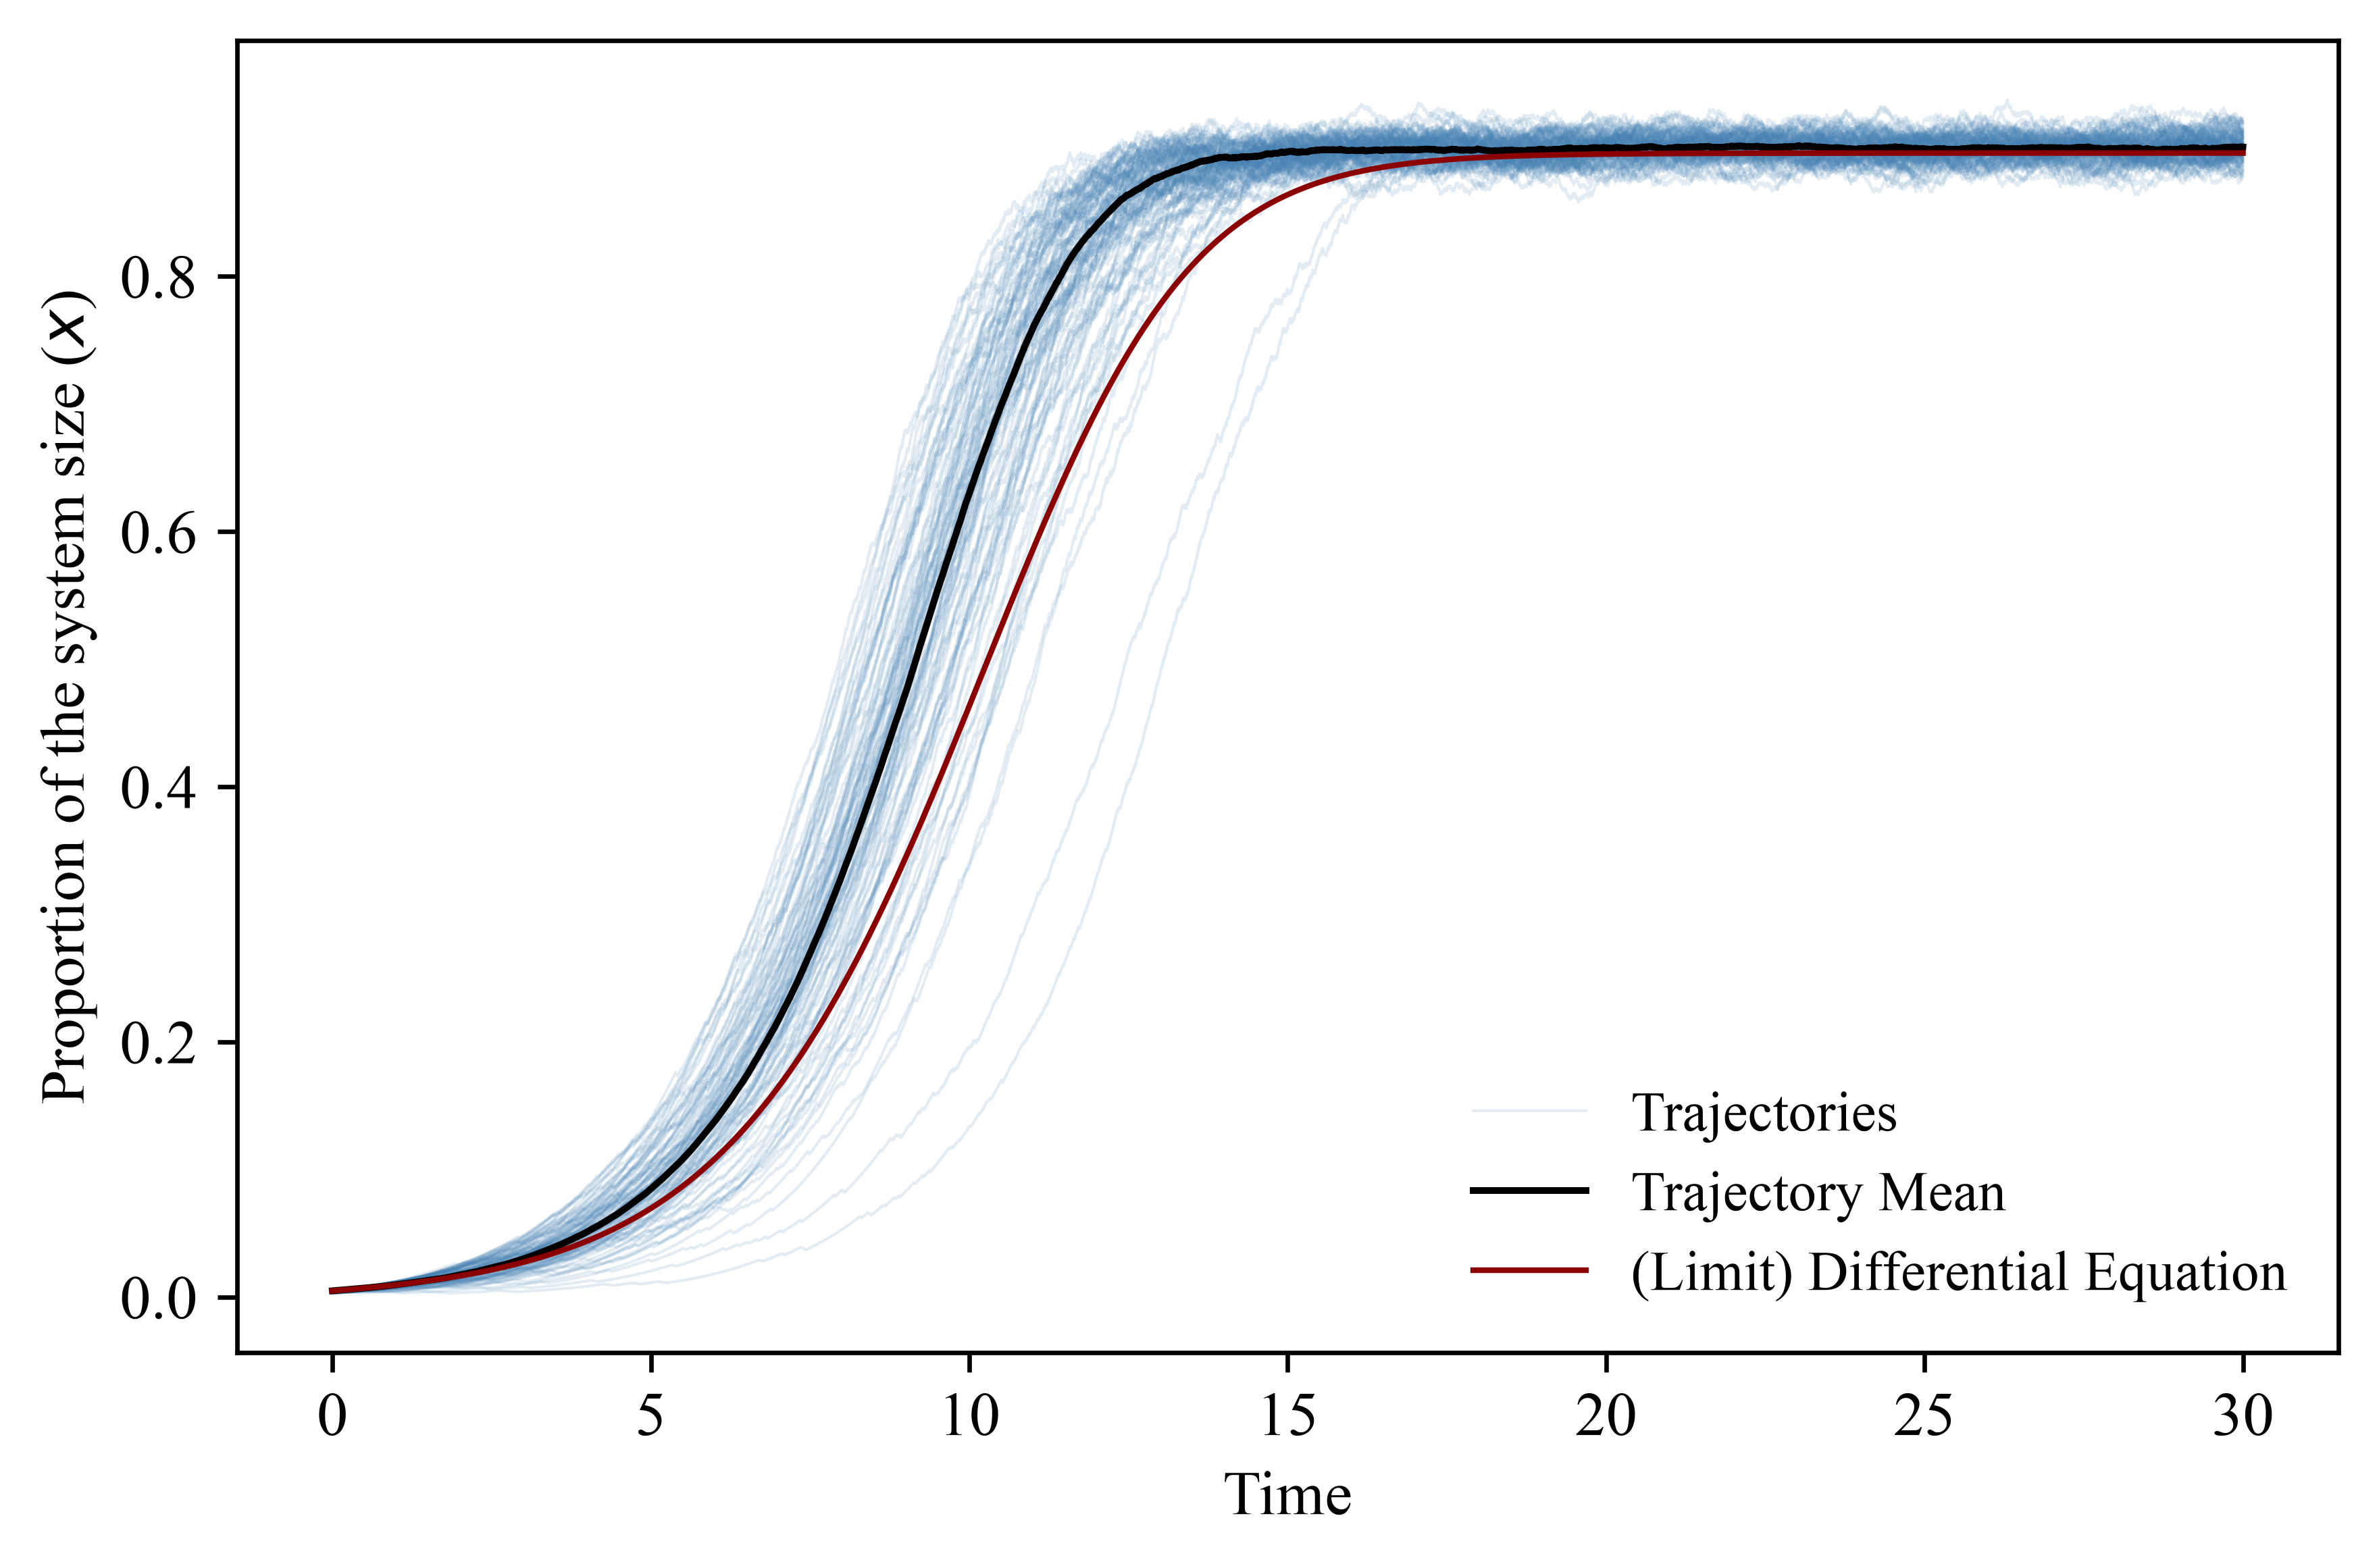

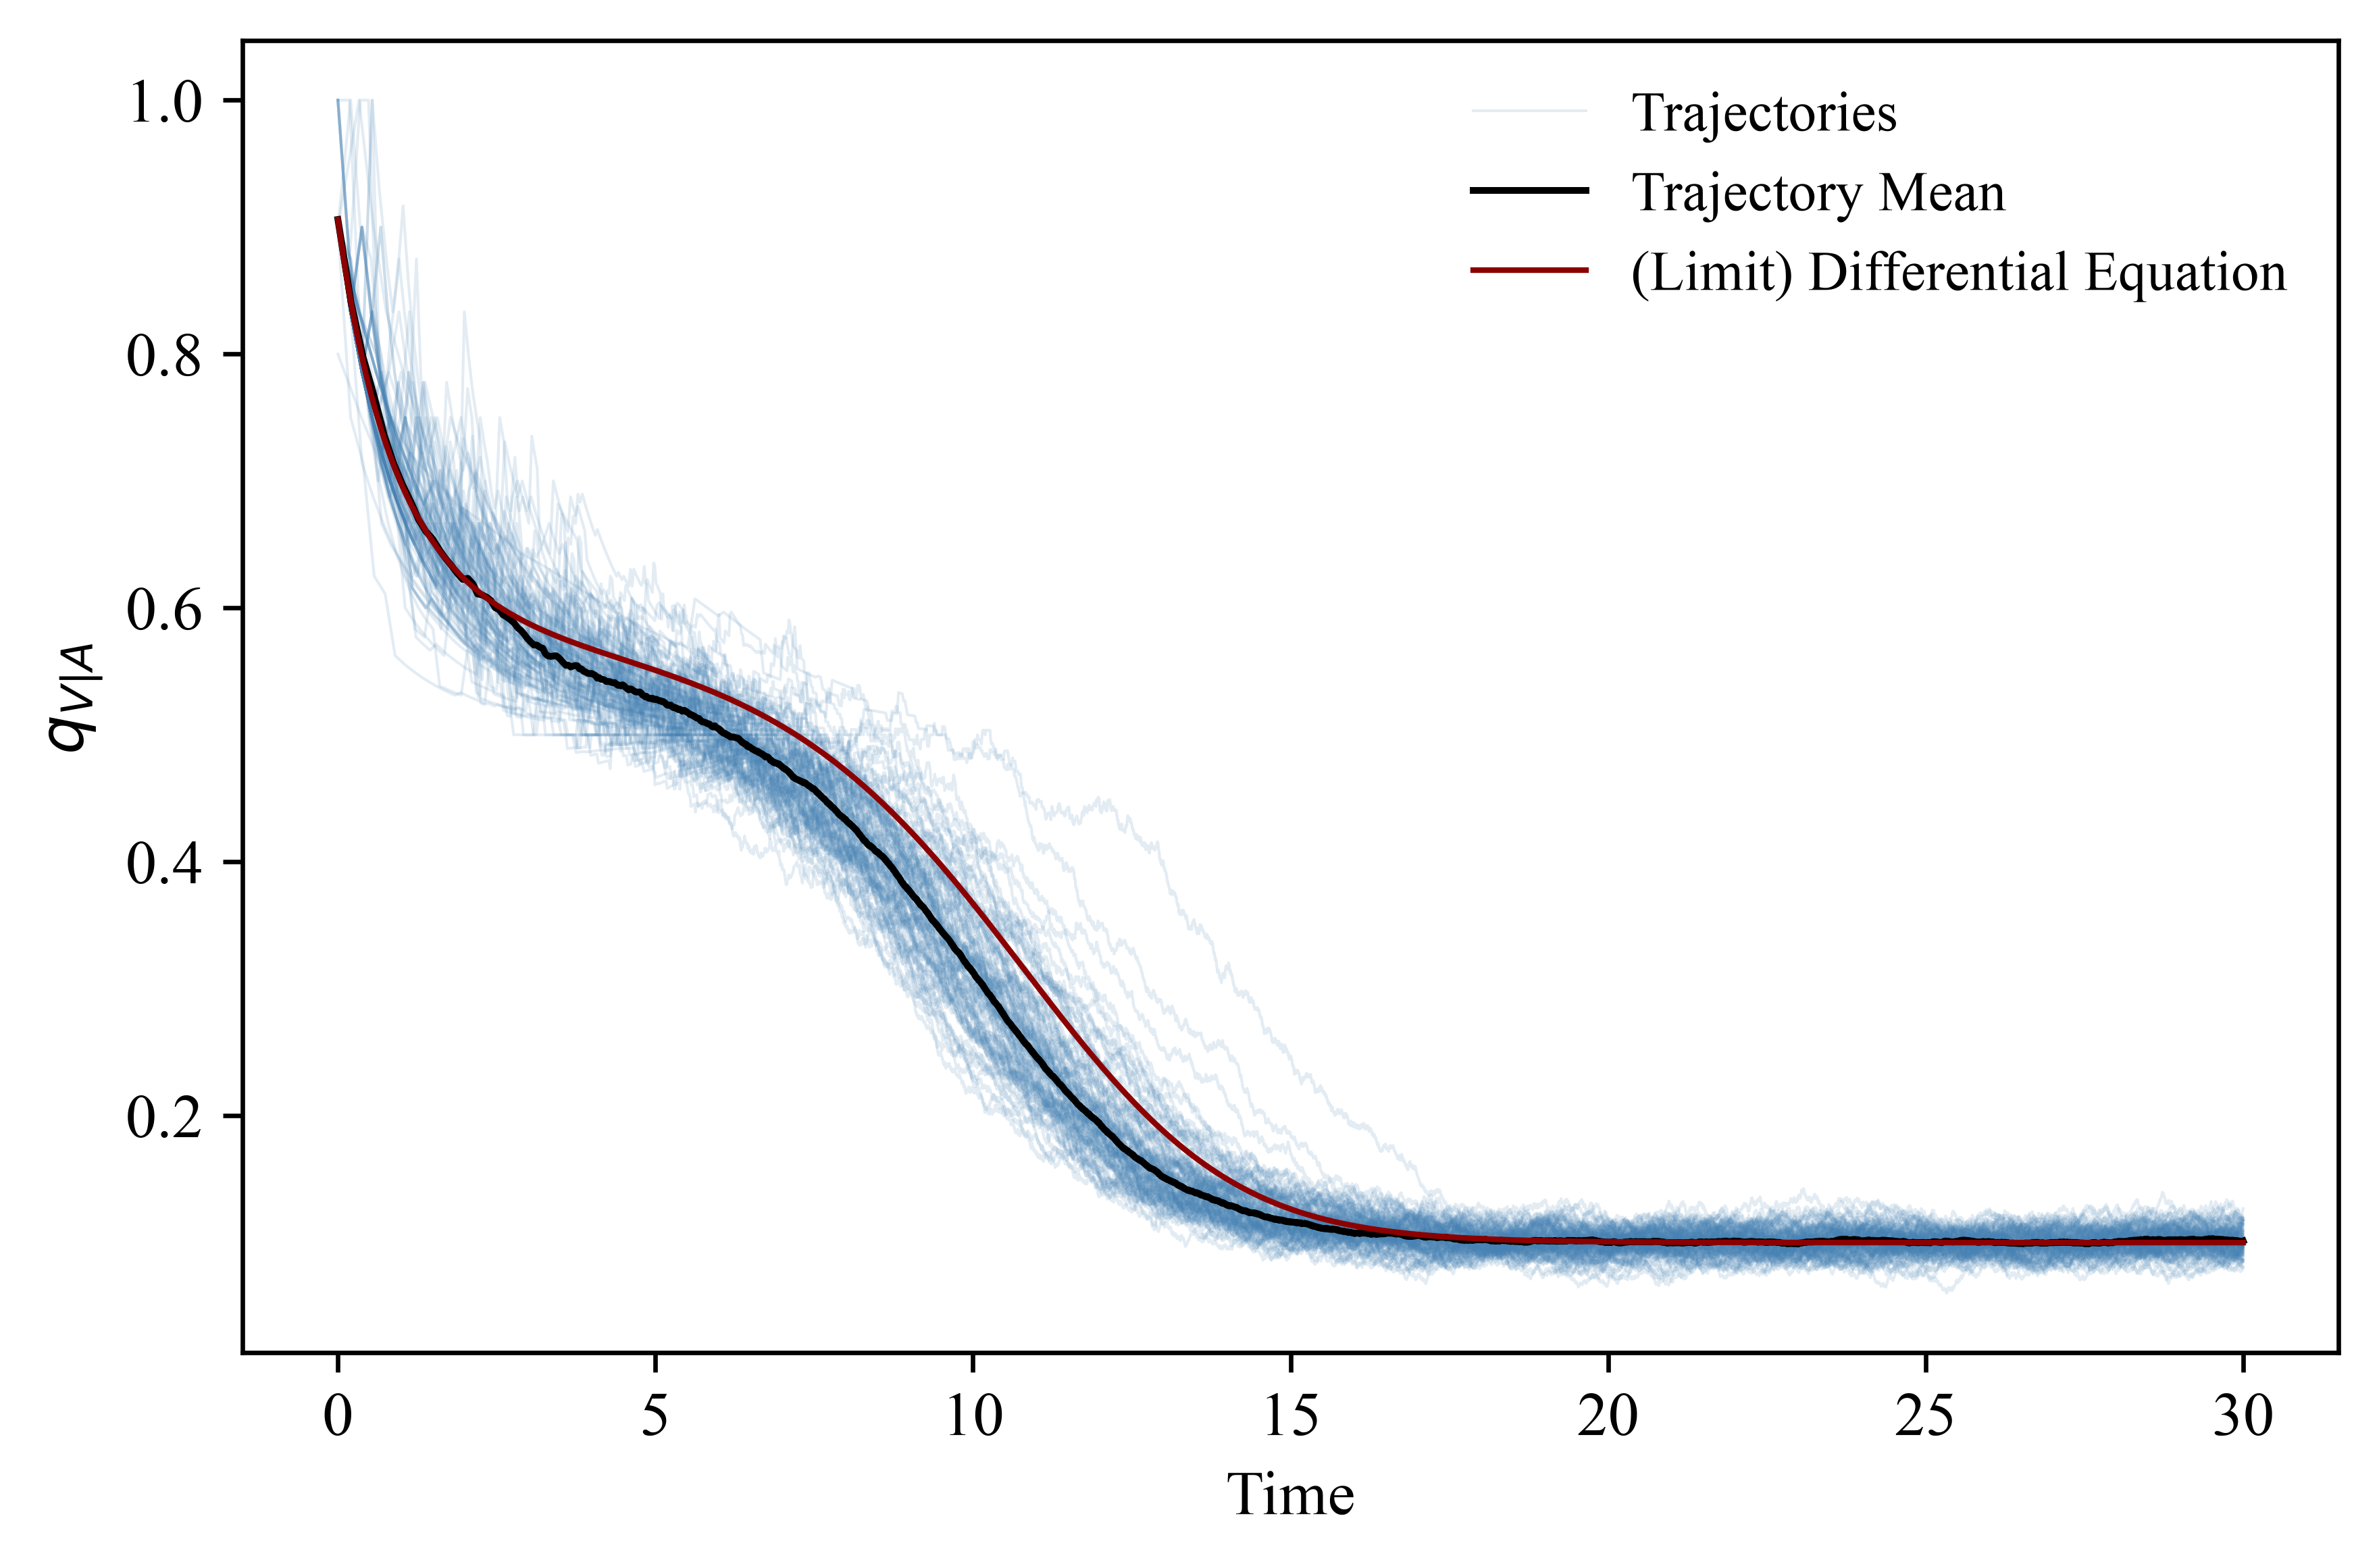

In [ ]:
# save_fig = False
# timestop_for_plotting = 30
# graph_type=="Regular"

# f1 = plt.figure(1,figsize=(6, 4), dpi=600)
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "font.size": 11,
#     "axes.linewidth": 0.8
# })

# if graph_type=="Regular":

#     f2 = plt.figure(2,figsize=(6, 4), dpi=600)
#     plt.rcParams.update({
#         "font.family": "serif",
#         "font.serif": ["Times New Roman"],
#         "font.size": 11,
#         "axes.linewidth": 0.8
#     })


# label = True

# if graph_type=="Regular":
#     for traj,qav_traj,time_traj in zip(trajectories,qav_trajectories,time_trajectories):
#         times = [0]
#         for pa,qav in zip(traj[:-1],qav_traj[:-1]):
#             times.append(times[-1] + 1/(single_N*pa*(qav+single_d)))
#         times = [t for t in times if t<=timestop_for_plotting]
#         temp_traj = traj[:len(times)]
#         temp_qav_traj = qav_traj[:len(times)]
#         # times = [0]
#         # for pa in temp_traj[:-1]:
#         #     times.append(times[-1] + 1/(single_N*pa*((1-pa)+single_d)))
#         # times = time_traj[:timestop_for_plotting]
#         if label:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color='steelblue', alpha=0.15, linewidth=0.5,label="Trajectories")
#             plt.figure(2)
#             plt.plot(times,temp_qav_traj, color='steelblue', alpha=0.15, linewidth=0.5,label="Trajectories")
#             label=False
#         else:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color='steelblue', alpha=0.15, linewidth=0.5)
#             plt.figure(2)
#             plt.plot(times,temp_qav_traj, color='steelblue', alpha=0.15, linewidth=0.5)
# else:
#     for traj in trajectories:
#         if traj[-1]==0.001:
#             print(traj)
#             continue
#         # temp_traj = np.array(traj[:timestop_for_plotting])
#         times = [0]
#         for pa in traj[:-1]:
#             times.append(times[-1] + 1/(single_N*pa*((1-pa)+single_d)))
#         times = [t for t in times if t<=timestop_for_plotting]
#         temp_traj = traj[:len(times)]
#         # times = time_traj[:timestop_for_plotting]
#         if label:
#             plt.plot(times, temp_traj, color='steelblue', alpha=0.05, linewidth=0.5,label="Trajectories")
            
#             label=False
#         else:
#             plt.plot(times, temp_traj, color='steelblue', alpha=0.05, linewidth=0.5)
            

# trajectories = np.array(trajectories)
# traj_mean = np.mean(trajectories, axis=0)
# # times = np.mean(time_trajectories,axis=0)[:timestop_for_plotting]
# times = [0]
# if graph_type=="Regular":
#     qav_trajectories = np.array(qav_trajectories)
#     qav_mean = np.mean(qav_trajectories,axis=0)
#     for pa,qav in zip(traj_mean[:-1],qav_mean[:-1]):
#         times.append(times[-1] + 1/(single_N*pa*(qav+single_d)))
#     times = [t for t in times if t<=timestop_for_plotting]
#     traj_mean = traj_mean[:len(times)]
#     qav_mean = qav_mean[:len(times)]
#     plt.figure(1)
#     plt.plot(times, traj_mean, color='black', linewidth=1.2, label='Trajectory Mean')
#     plt.figure(2)
#     plt.plot(times, qav_mean, color='black', linewidth=1.2, label='Trajectory Mean')
# else:
#     for pa in traj_mean[:-1]:
#         times.append(times[-1] + 1/(single_N*pa*((1-pa)+single_d)))
#     times = [t for t in times if t<=timestop_for_plotting]
#     traj_mean = traj_mean[:len(times)]
#     plt.plot(times, traj_mean, color='black', linewidth=1.2, label='Trajectory Mean')




# if graph_type =="Well-mixed":
#     multiplier = 1
#     x0 = np.mean(trajectories[:,0])
#     K = 1 - single_d
#     growth = 1 - single_d
#     dt = 0.01
#     x_vals, t_vals = [], []
#     t = 0
#     p_nought_k_nought_term = (x0)/(K-x0)
#     while t<max(times):

#         # x_vals.append(K / (1 + (K - x0) / x0 * np.exp(-growth * t)))
#         x_vals.append((p_nought_k_nought_term*K*np.exp(growth*t))/(1+p_nought_k_nought_term*np.exp(growth*t)))
#         t_vals.append(t)
#         t += dt
#     plt.plot(np.array(t_vals)*multiplier, x_vals, color='darkred', linewidth=1.0, label='Logistic Equation')
# else:
#     multiplier = 1
#     x0 = np.mean(trajectories[:, 0])
#     q0 = np.mean(qav_trajectories[:, 0])
#     k=ks[0]

#     def dxdt(x, q):
#         return (q - single_d) * x

#     def dqdt(x, q):
#         return single_d * (1 -  q) + q / (k * (x - 1)) * (k * (q +  q * x + x - 1) - 2* (q * x + x - 1))

#     K = 1 - single_d
#     growth = 1 - single_d
#     dt = 0.001
#     t0 = 0

#     x_vals, q_vals, t_vals = [x0], [q0], [t0]

#     while t_vals[-1] < max(times):
#         prev_x = x_vals[-1]
#         prev_q = q_vals[-1]
#         t = t_vals[-1]

#         # Runge-Kutta 4th order method
#         k1_x = dxdt(prev_x, prev_q)
#         k1_q = dqdt(prev_x, prev_q)

#         k2_x = dxdt(prev_x + 0.5 * dt * k1_x, prev_q + 0.5 * dt * k1_q)
#         k2_q = dqdt(prev_x + 0.5 * dt * k1_x, prev_q + 0.5 * dt * k1_q)

#         k3_x = dxdt(prev_x + 0.5 * dt * k2_x, prev_q + 0.5 * dt * k2_q)
#         k3_q = dqdt(prev_x + 0.5 * dt * k2_x, prev_q + 0.5 * dt * k2_q)

#         k4_x = dxdt(prev_x + dt * k3_x, prev_q + dt * k3_q)
#         k4_q = dqdt(prev_x + dt * k3_x, prev_q + dt * k3_q)

#         next_x = prev_x + (dt / 6) * (k1_x + 2 * k2_x + 2 * k3_x + k4_x)
#         next_q = prev_q + (dt / 6) * (k1_q + 2 * k2_q + 2 * k3_q + k4_q)

#         x_vals.append(next_x)
#         q_vals.append(next_q)
#         t_vals.append(t + dt)

#     # Plot
#     plt.figure(1)
#     plt.plot(np.array(t_vals) * multiplier, x_vals, color='darkred', linewidth=1.0, label='(Limit) Differential Equation')
#     plt.figure(2)
#     plt.plot(np.array(t_vals) * multiplier, q_vals, color='darkred', linewidth=1.0, label='(Limit) Differential Equation')

# plt.figure(1)
# plt.xlabel("Time", fontsize=11)
# plt.ylabel("Proportion of the system size ($x$)", fontsize=11)
# plt.legend(frameon=False, fontsize=10)
# plt.grid(False)
# plt.tight_layout()

# if save_fig and graph_type=="Well-mixed":
#     plt.savefig("trajectory_from_1.pdf", bbox_inches='tight')

# if graph_type=="Regular":
#     plt.figure(2)
#     plt.xlabel("Time", fontsize=11)
#     plt.ylabel("$q_{V|A}$", fontsize=11)
#     plt.legend(frameon=False, fontsize=10)
#     plt.grid(False)
#     plt.tight_layout()

#     if save_fig:
#         plt.savefig("qav_trajectory_from_1_regular.pdf", bbox_inches='tight')
#         plt.figure(1)
#         plt.savefig("trajectory_from_1_regular.pdf", bbox_inches='tight')

# plt.show()

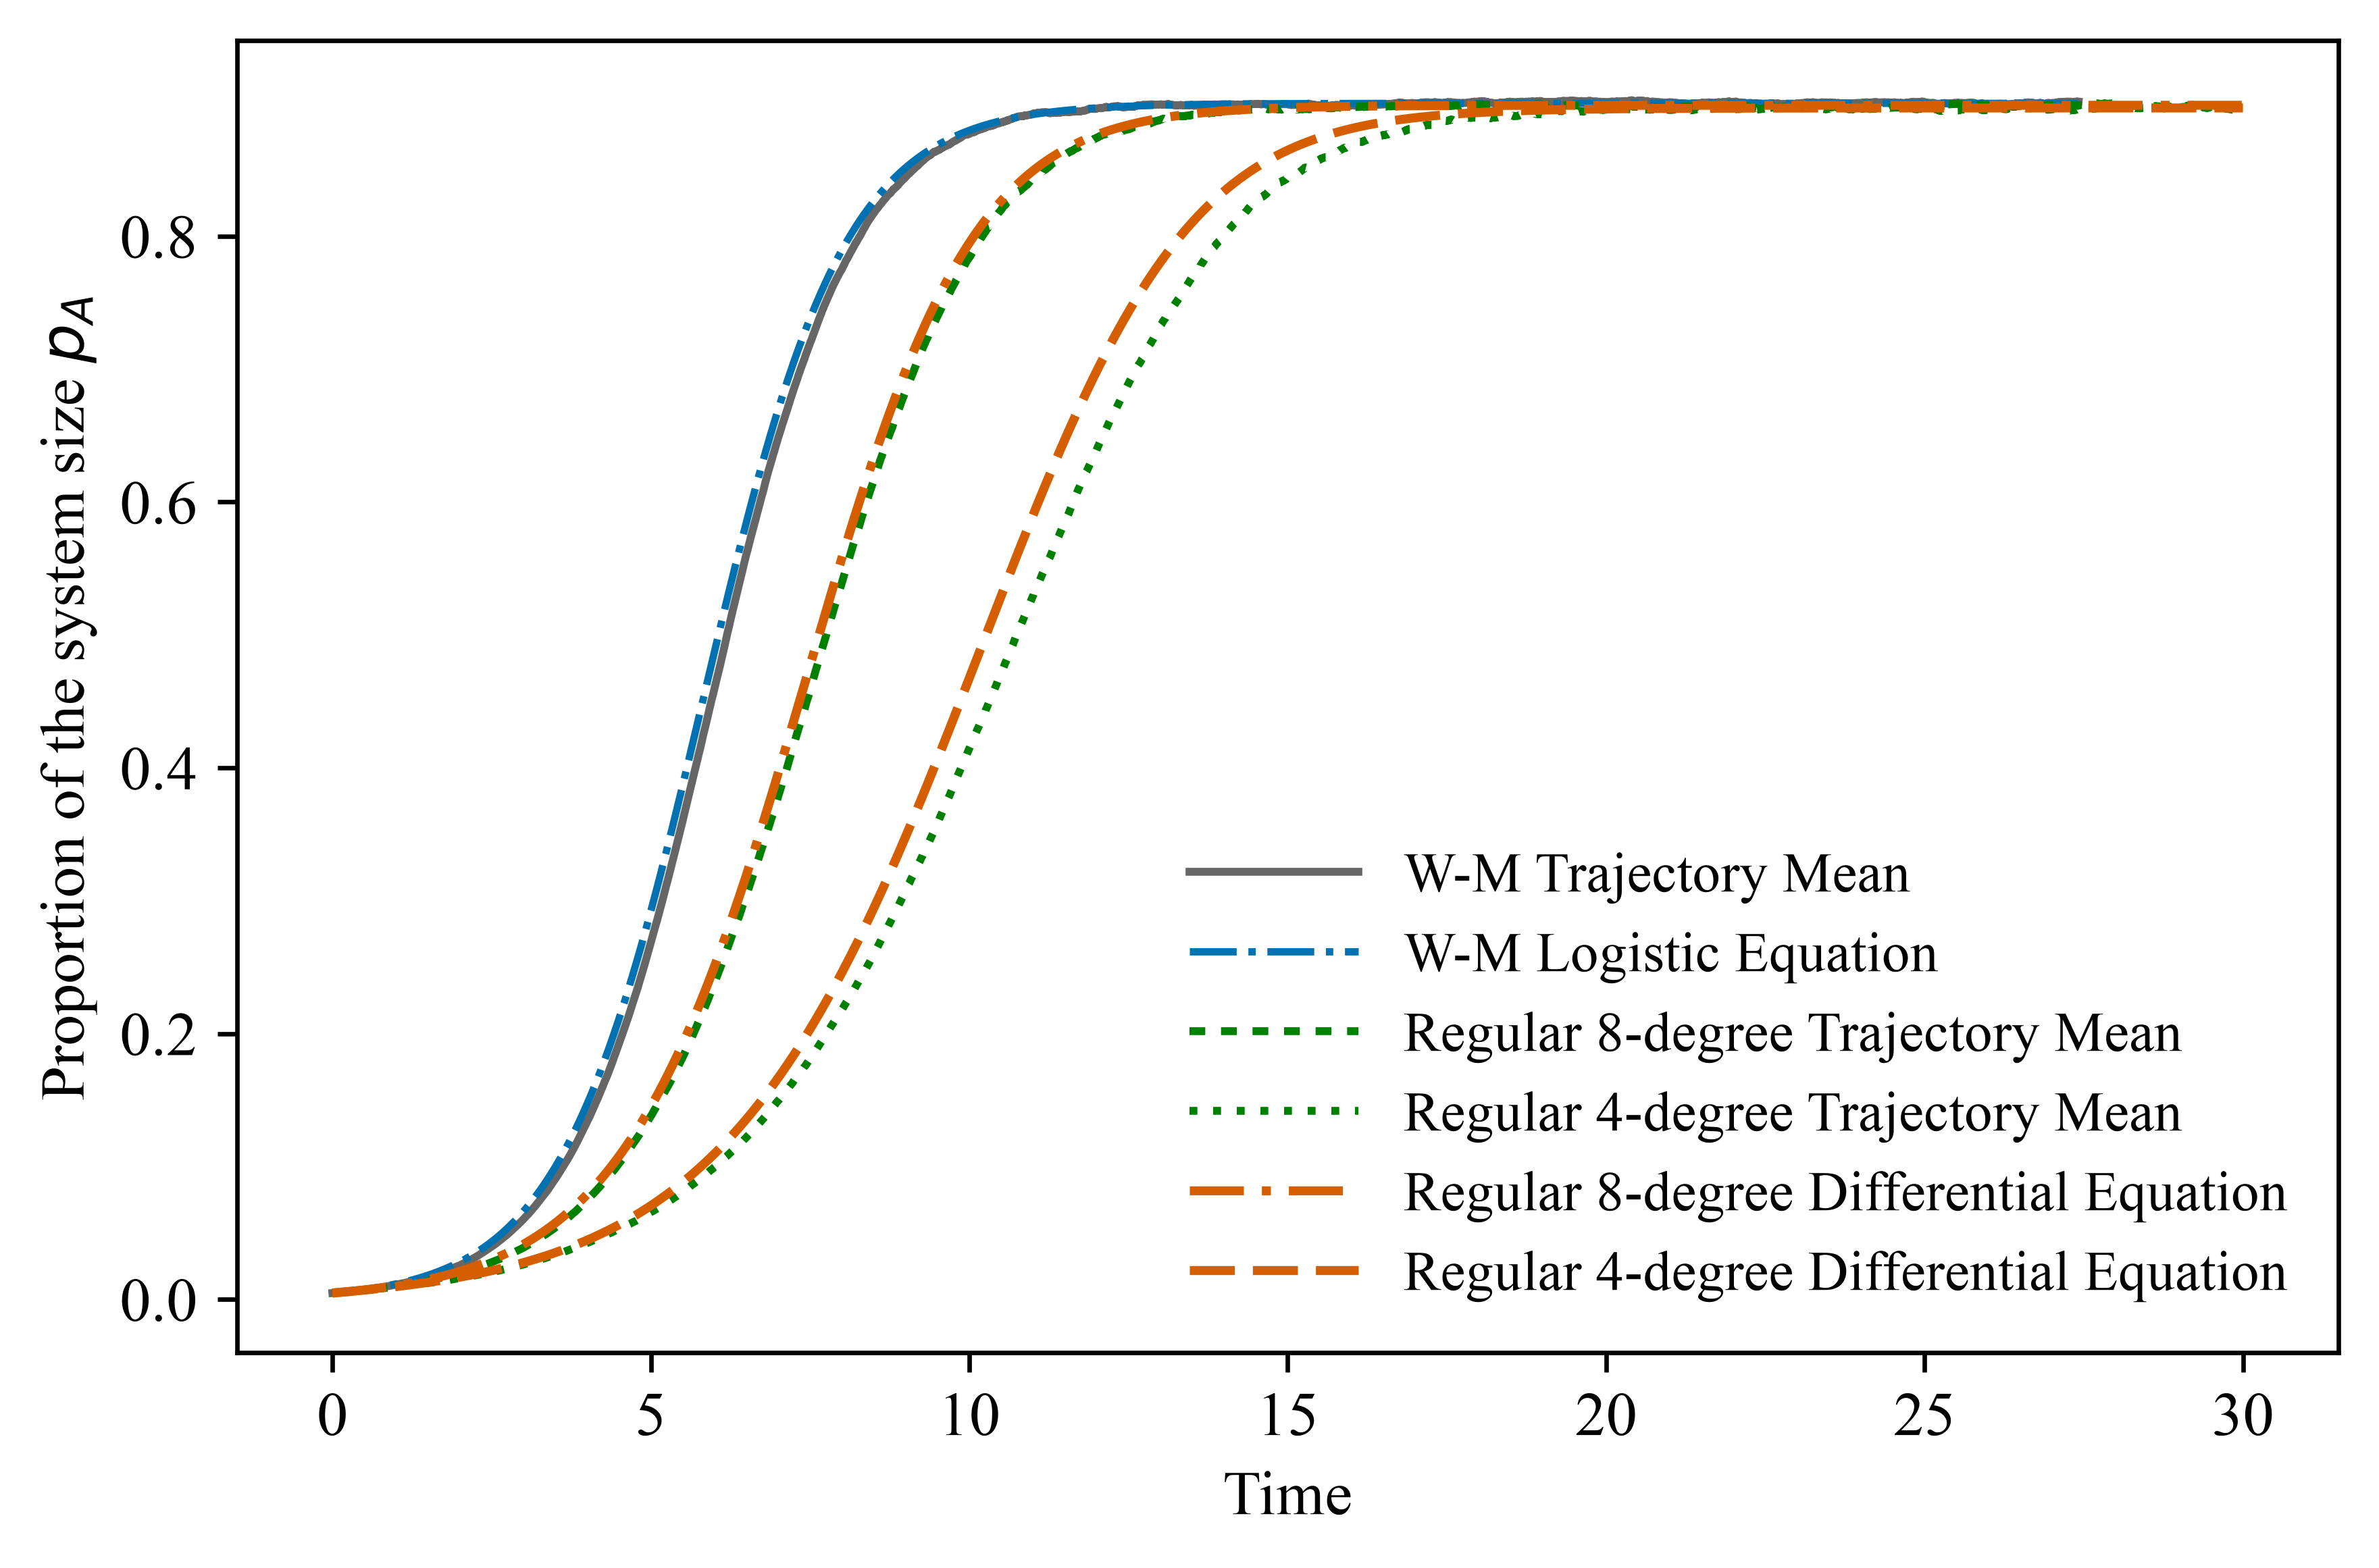

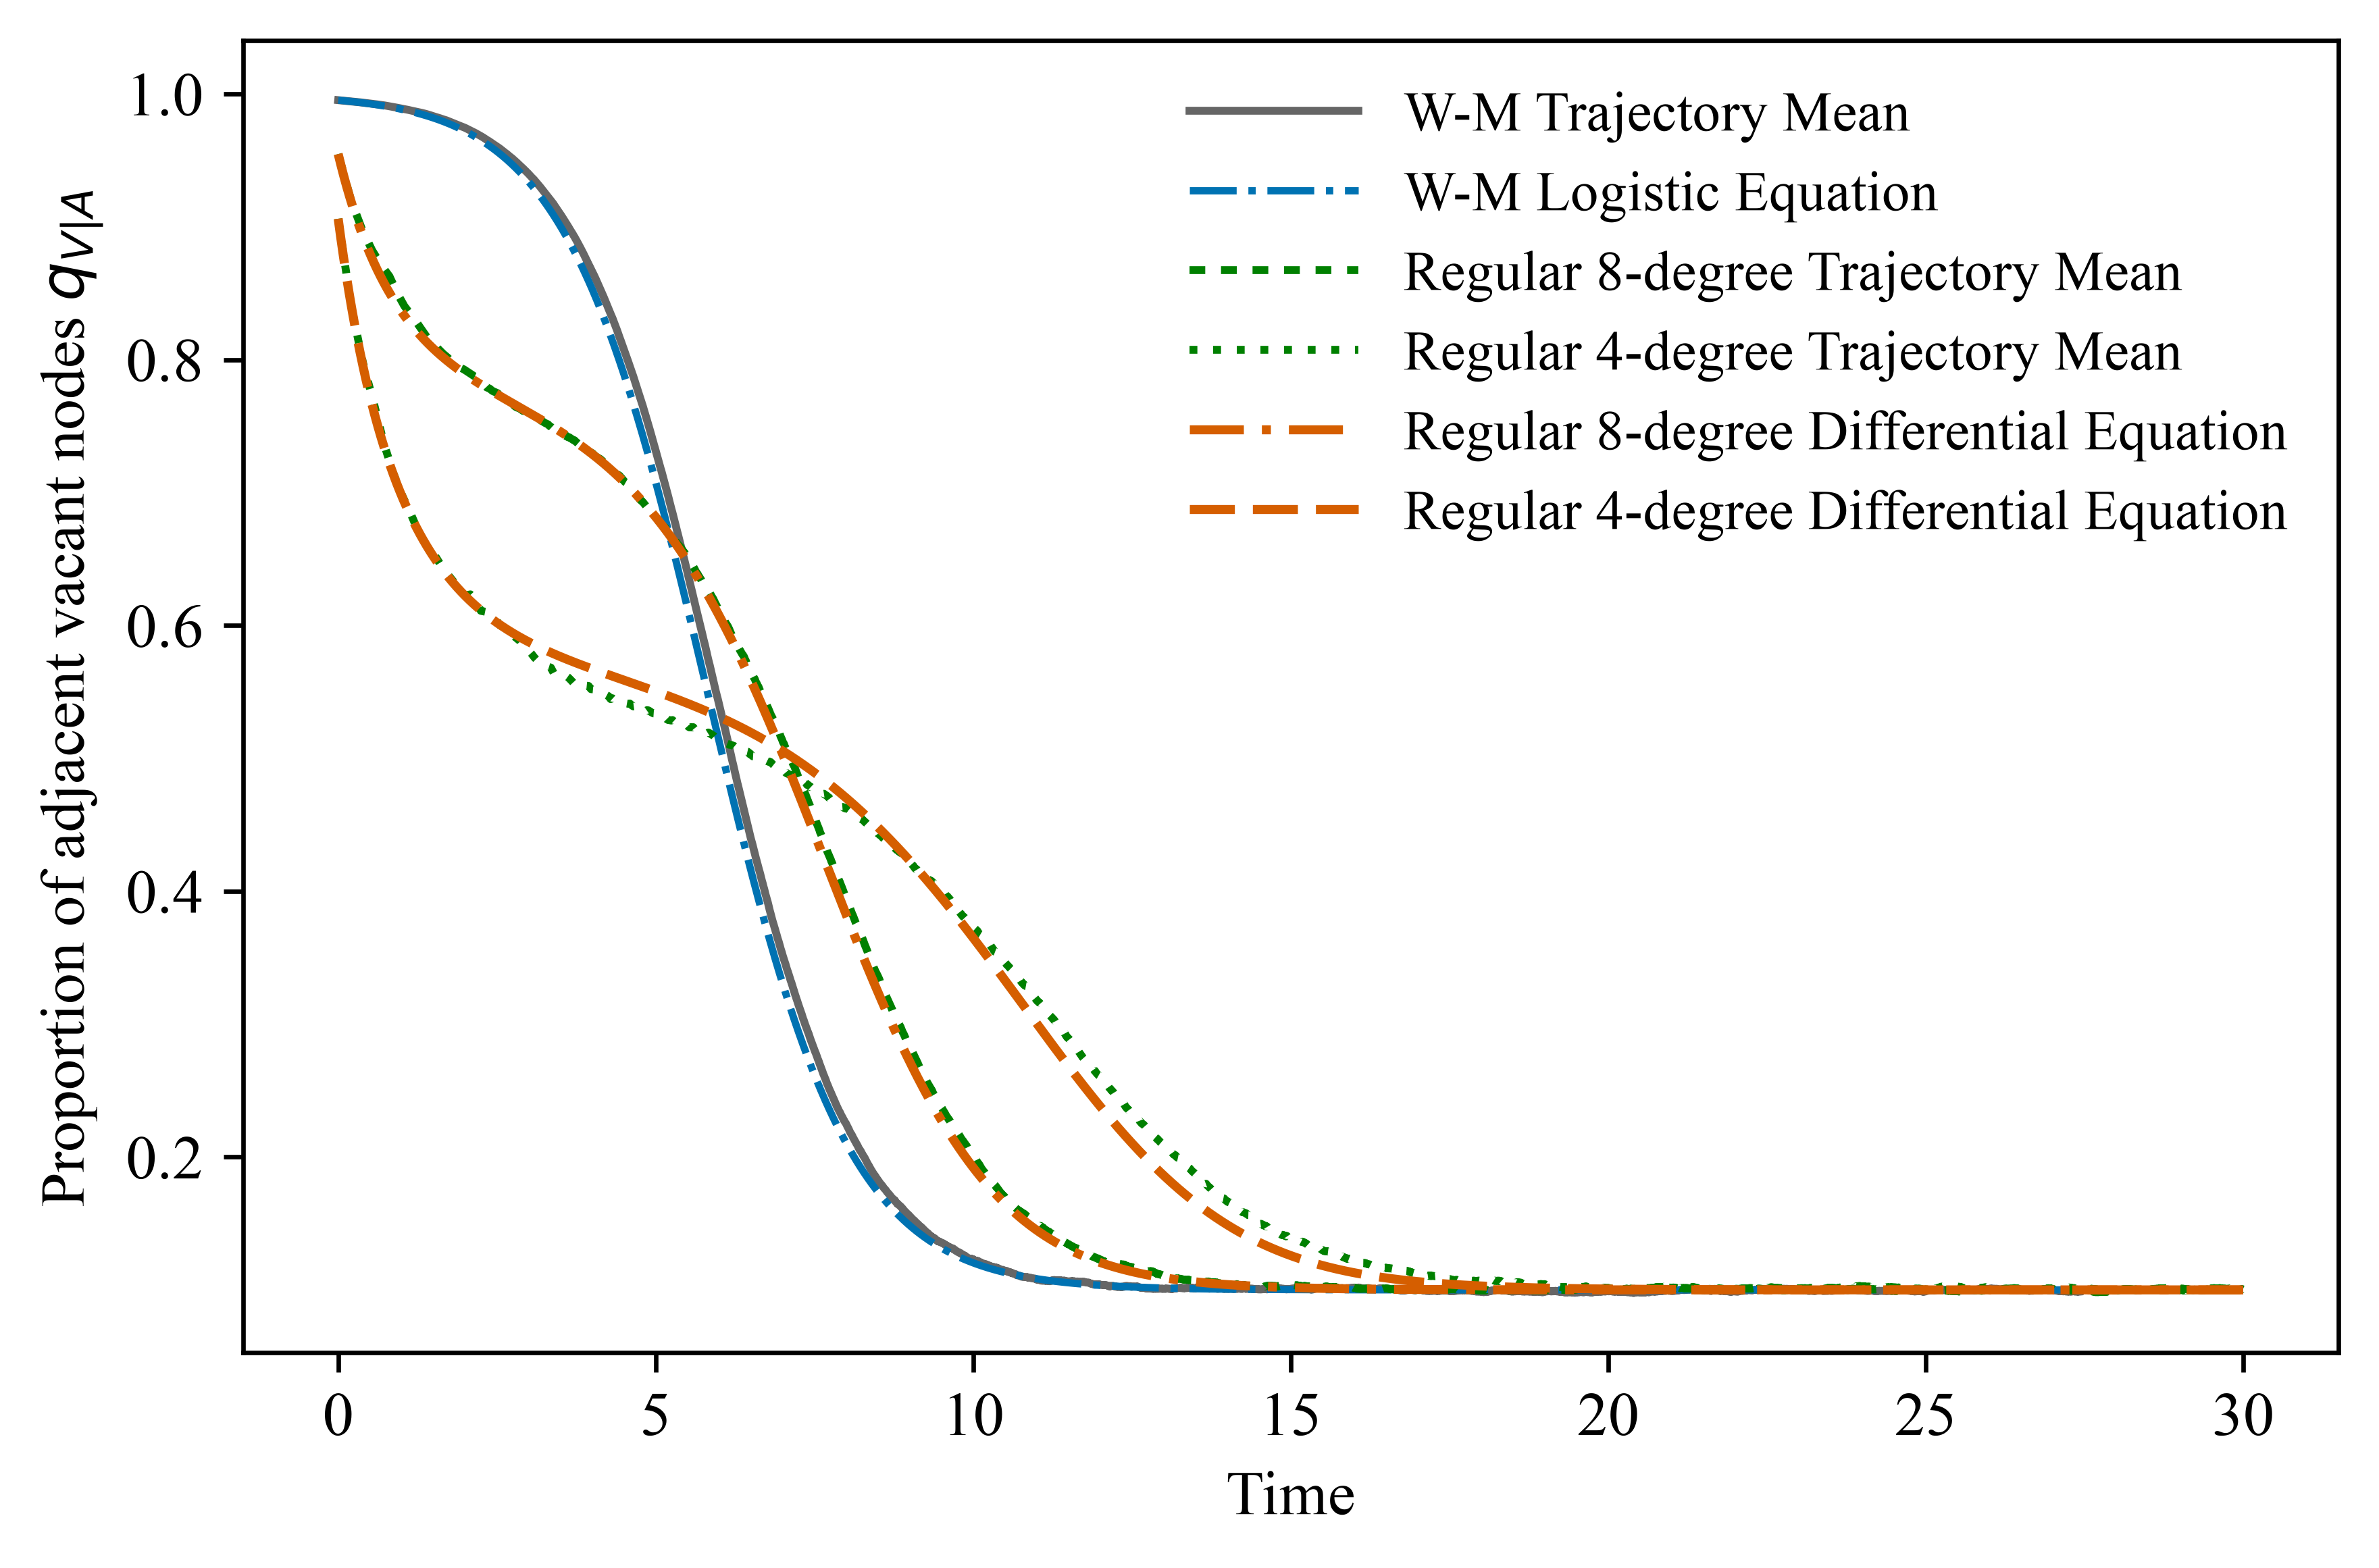

In [ ]:
# save_fig = False
# timestop_for_plotting = 30
# graphs = [{"code":f"r8","name":"Regular 8-degree"}, {"code":f"r4","name":"Regular 4-degree"}]


# import matplotlib.pyplot as plt
# import numpy as np

# # ------------------------------------------------------------------
# # Styling (added)
# # ------------------------------------------------------------------
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "font.size": 11,
#     "axes.linewidth": 0.8
# })

# colors = {
#     "traj": "#B8C7D9",        # light blue-grey
#     "mean": "green",          # green
#     "wm_mean": "#666666",     # dark grey
#     "wm_logistic": "#0072B2", # blue
#     "limit": "#D55E00"        # vermillion
# }

# linestyles = {
#     "wm_mean": "-",         # solid (reference WM mean)
    
#     "wm_logistic": "-.",    # dash-dot (model approximation)

#     "4-mean": (0, (1, 2)),  # dotted
#     "8-mean": (0, (2, 2)),  # short dashed

#     "4-limit": (0, (5, 2)), # long dashed
#     "8-limit": (0, (6, 2, 1, 2)),  # dash-dot-dot (distinct pattern)
# }

# # ------------------------------------------------------------------

# f1 = plt.figure(1, figsize=(6, 4), dpi=600)

# if graph_type == "Regular":
#     f2 = plt.figure(2, figsize=(6, 4), dpi=600)

# label = True
# plotting_trajectories = False

# if plotting_trajectories:
#     for traj, qav_traj, time_traj in zip(trajectories, qav_trajectories, time_trajectories):

#         times = [0]
#         for pa, qav in zip(traj[:-1], qav_traj[:-1]):
#             times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

#         times = [t for t in times if t <= timestop_for_plotting]
#         temp_traj = traj[:len(times)]
#         temp_qav_traj = qav_traj[:len(times)]

#         if label:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color=colors["traj"], alpha=0.15, linewidth=0.5, label="Trajectories")
#             plt.figure(2)
#             plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=0.15, linewidth=0.5, label="Trajectories")
#             label = False
#         else:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color=colors["traj"], alpha=0.15, linewidth=0.5)
#             plt.figure(2)
#             plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=0.15, linewidth=0.5)

#     for traj in wm_trajectories:
#         if traj[-1] == 0.001:
#             print(traj)
#             continue

#         times = [0]
#         for pa in traj[:-1]:
#             times.append(times[-1] + 1/(single_N * pa * ((1 - pa) + single_d)))

#         times = [t for t in times if t <= timestop_for_plotting]
#         temp_traj = traj[:len(times)]

#         if label:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color=colors["traj"], alpha=0.05, linewidth=0.5, label="Trajectories")
#             label = False
#         else:
#             plt.figure(1)
#             plt.plot(times, temp_traj, color=colors["traj"], alpha=0.05, linewidth=0.5)

# # ------------------------------------------------------------------
# # Means
# # ------------------------------------------------------------------


# wm_trajectories = np.array(wm_trajectories)
# wm_traj_mean = np.mean(wm_trajectories, axis=0)

# # ------------------------------------------------------------------
# # WM mean
# # ------------------------------------------------------------------

# wm_times = [0]
# for pa in traj_mean[:-1]:
#     wm_times.append(wm_times[-1] + 1/(single_N * pa * ((1 - pa) + single_d)))
# wm_times = [t for t in wm_times if t <= timestop_for_plotting]
# wm_traj_mean = wm_traj_mean[:len(wm_times)]

# plt.figure(1)
# plt.plot(wm_times, wm_traj_mean, color=colors["wm_mean"], linestyle=linestyles["wm_mean"],
#          linewidth=1.4, label='W-M Trajectory Mean')

# plt.figure(2)
# plt.plot(wm_times, 1 - wm_traj_mean, color=colors["wm_mean"], linestyle=linestyles["wm_mean"],
#          linewidth=1.4, label='W-M Trajectory Mean')
# # ------------------------------------------------------------------
# # Logistic approximation
# # ------------------------------------------------------------------

# multiplier = 1
# x0 = np.mean(wm_trajectories[:, 0])
# K = 1 - single_d
# growth = 1 - single_d
# dt = 0.01

# p_nought_k_nought_term = (x0) / (K - x0)

# x_vals, t_vals = [], []
# t = 0

# while t < max(wm_times):
#     x_vals.append((p_nought_k_nought_term * K * np.exp(growth * t)) /
#                   (1 + p_nought_k_nought_term * np.exp(growth * t)))
#     t_vals.append(t)
#     t += dt

# plt.figure(1)
# plt.plot(np.array(t_vals)*multiplier, x_vals,
#          color=colors["wm_logistic"], linestyle=linestyles["wm_logistic"],
#          linewidth=1.3, label='W-M Logistic Equation')

# plt.figure(2)
# plt.plot(np.array(t_vals)*multiplier, 1 - np.array(x_vals),
#          color=colors["wm_logistic"], linestyle=linestyles["wm_logistic"],
#          linewidth=1.3, label='W-M Logistic Equation')


# for graph in graphs:
#     trajectories = all_reg_trajectories[graph['name']]
#     qav_trajectories = all_reg_qav_trajectories[graph['name']]

#     trajectories = np.array(trajectories)
#     traj_mean = np.mean(trajectories, axis=0)

#     qav_trajectories = np.array(qav_trajectories)
#     qav_mean = np.mean(qav_trajectories, axis=0)


#     times = [0]
#     for pa, qav in zip(traj_mean[:-1], qav_mean[:-1]):
#         times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

#     times = [t for t in times if t <= timestop_for_plotting]
#     traj_mean = traj_mean[:len(times)]
#     qav_mean = qav_mean[:len(times)]

#     plt.figure(1)
#     plt.plot(times, traj_mean, color=colors["mean"], linestyle=linestyles[f"{graph['code'][1:]}-mean"],
#             linewidth=1.4, label=f'{graph["name"]} Trajectory Mean')

#     plt.figure(2)
#     plt.plot(times, qav_mean, color=colors["mean"], linestyle=linestyles[f"{graph['code'][1:]}-mean"],
#             linewidth=1.4, label=f'{graph["name"]} Trajectory Mean')
# # ------------------------------------------------------------------
# # ODE limit (RK4)
# # ------------------------------------------------------------------
# for graph in graphs:
#     trajectories = all_reg_trajectories[graph['name']]
#     qav_trajectories = all_reg_qav_trajectories[graph['name']]

#     trajectories = np.array(trajectories)
#     traj_mean = np.mean(trajectories, axis=0)

#     qav_trajectories = np.array(qav_trajectories)
#     qav_mean = np.mean(qav_trajectories, axis=0)

#     times = [0]
#     for pa, qav in zip(traj_mean[:-1], qav_mean[:-1]):
#         times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

#     times = [t for t in times if t <= timestop_for_plotting]
#     traj_mean = traj_mean[:len(times)]
#     qav_mean = qav_mean[:len(times)]
#     x0 = np.mean(trajectories[:, 0])
#     q0 = np.mean(qav_trajectories[:, 0])
#     k = int(graph['code'][1:])

#     def dxdt(x, q):
#         return (q - single_d) * x

#     def dqdt(x, q):
#         return single_d * (1 - q) + q / (k * (x - 1)) * (k * (q + q * x + x - 1) - 2 * (q * x + x - 1))

#     dt = 0.001
#     t_vals = [0]
#     x_vals = [x0]
#     q_vals = [q0]

#     while t_vals[-1] < max(times):
#         x = x_vals[-1]
#         q = q_vals[-1]

#         k1x, k1q = dxdt(x, q), dqdt(x, q)
#         k2x, k2q = dxdt(x + 0.5*dt*k1x, q + 0.5*dt*k1q), dqdt(x + 0.5*dt*k1x, q + 0.5*dt*k1q)
#         k3x, k3q = dxdt(x + 0.5*dt*k2x, q + 0.5*dt*k2q), dqdt(x + 0.5*dt*k2x, q + 0.5*dt*k2q)
#         k4x, k4q = dxdt(x + dt*k3x, q + dt*k3q), dqdt(x + dt*k3x, q + dt*k3q)

#         x_vals.append(x + dt*(k1x + 2*k2x + 2*k3x + k4x)/6)
#         q_vals.append(q + dt*(k1q + 2*k2q + 2*k3q + k4q)/6)
#         t_vals.append(t_vals[-1] + dt)

#     plt.figure(1)
#     plt.plot(np.array(t_vals)*multiplier, x_vals,
#             color=colors["limit"], linestyle=linestyles[f"{graph['code'][1:]}-limit"],
#             linewidth=1.6, label=f'{graph["name"]} Differential Equation')
#     plt.ylabel("Proportion of the system size $p_A$", fontsize=11)

#     plt.figure(2)
#     plt.plot(np.array(t_vals)*multiplier, q_vals,
#             color=colors["limit"], linestyle=linestyles[f"{graph['code'][1:]}-limit"],
#             linewidth=1.6, label=f'{graph["name"]} Differential Equation')
#     plt.ylabel("Proportion of adjacent vacant nodes $q_{V|A}$", fontsize=11)

# # ------------------------------------------------------------------
# # Formatting
# # ------------------------------------------------------------------

# for i in [1, 2]:
#     plt.figure(i)
#     plt.xlabel("Time", fontsize=11)
#     plt.legend(frameon=False, fontsize=10, handlelength=3)
#     plt.grid(False)
#     plt.tight_layout()


# if save_fig:
#     plt.figure(1)
#     plt.savefig("trajectory_from_1_combined.pdf", bbox_inches='tight')
#     plt.figure(2)
#     plt.savefig("qav_trajectory_from_1_combined.pdf", bbox_inches='tight')
# plt.show()

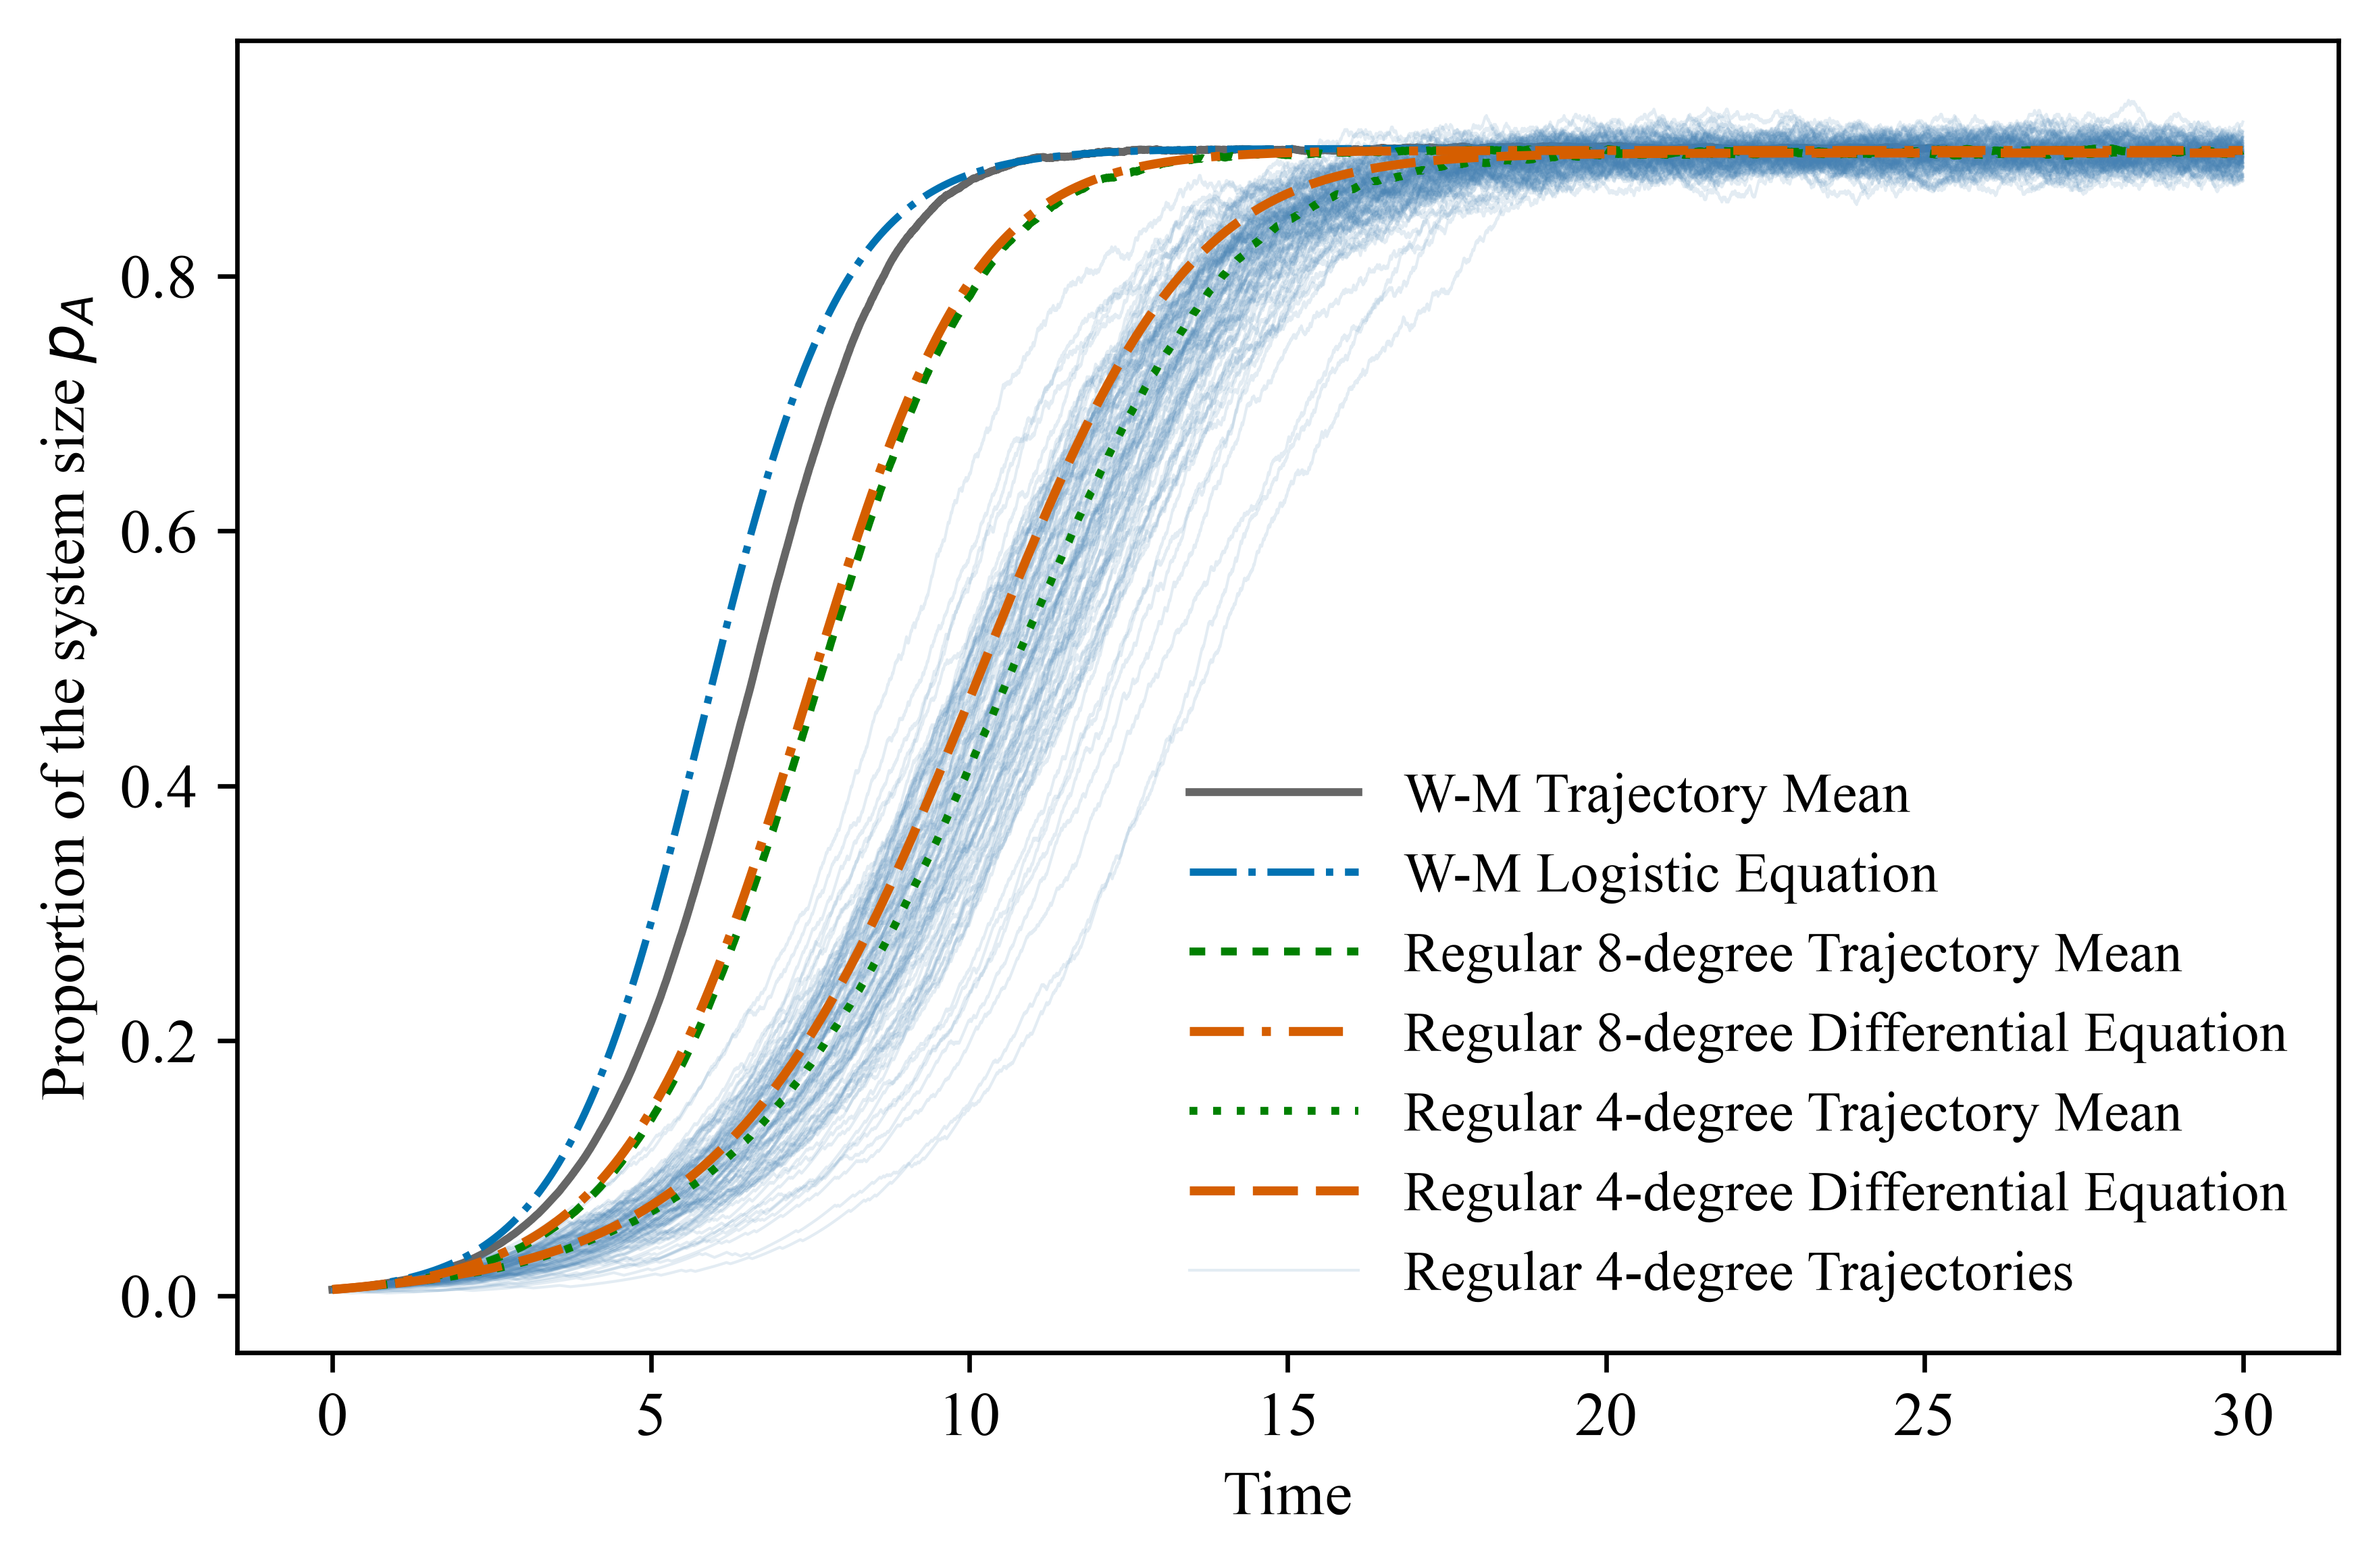

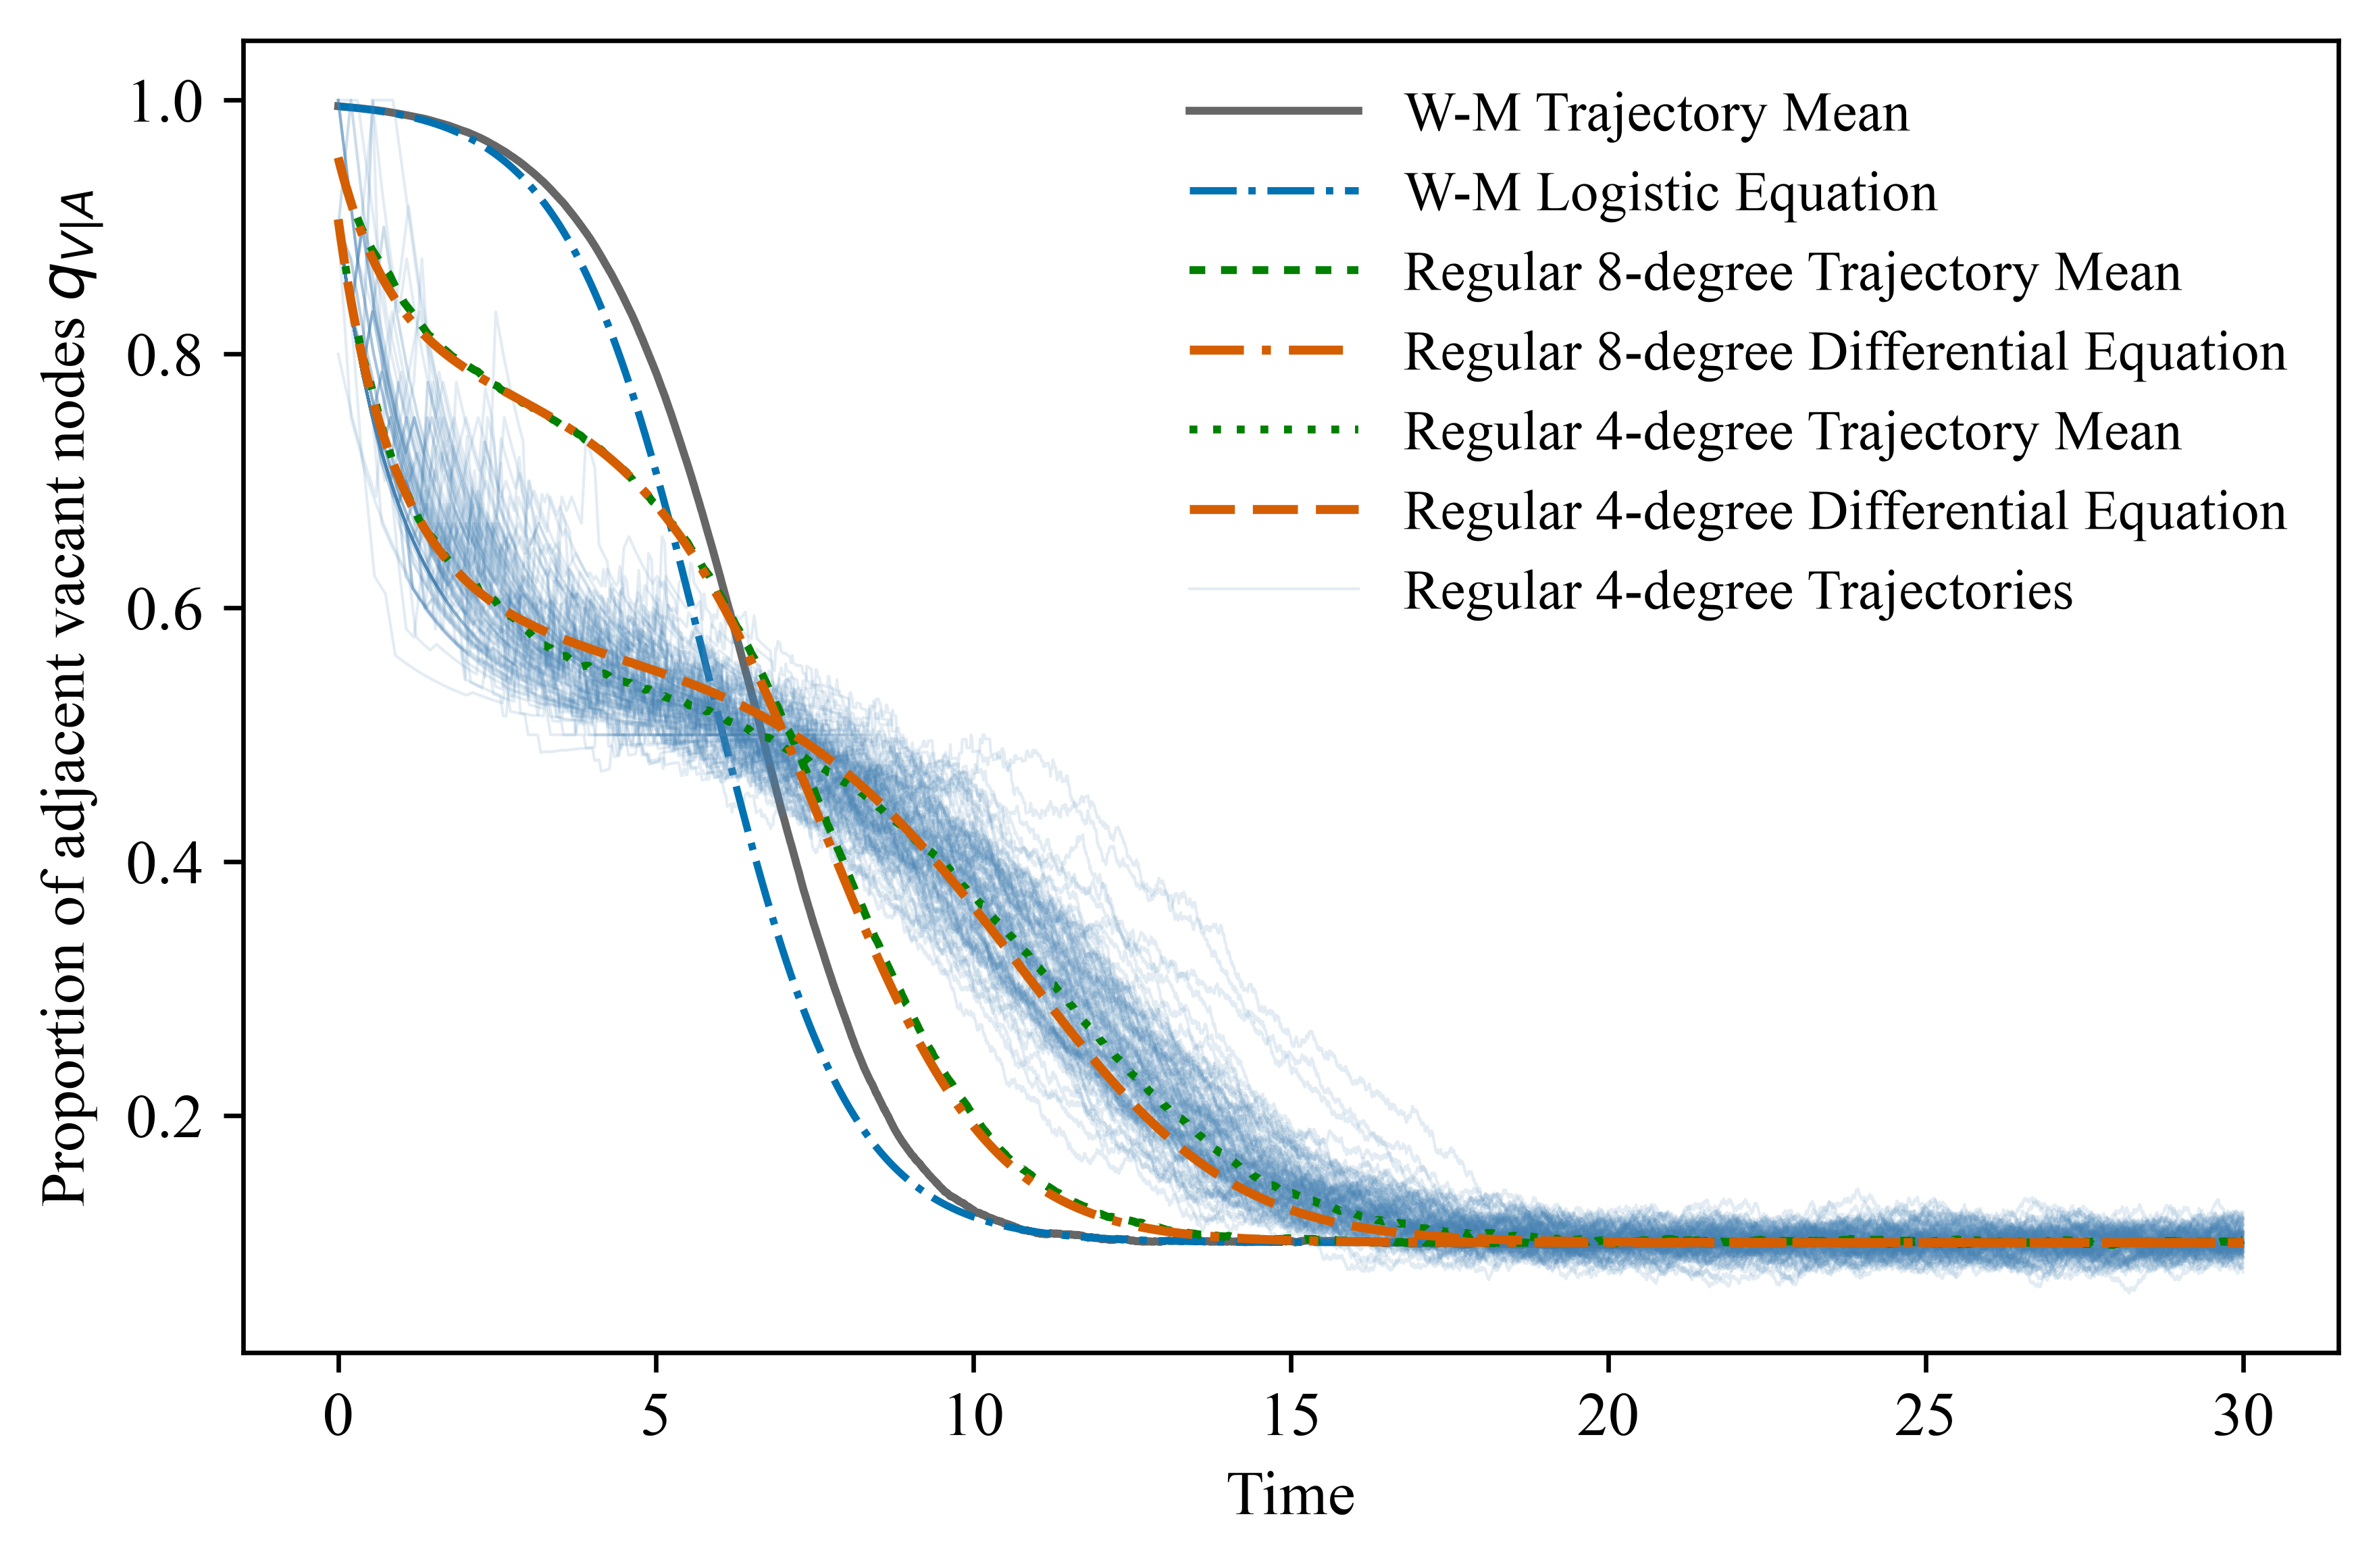

In [18]:
save_fig = True
timestop_for_plotting = 30
graphs = [ {"code":f"r4","name":"Regular 4-degree"},{"code":f"r8","name":"Regular 8-degree"}]

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------------
# Styling (added)
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "axes.linewidth": 0.8
})

colors = {
    "traj": "steelblue",        # light blue-grey
    "mean": "green",          # green
    "wm_mean": "#666666",     # dark grey
    "wm_logistic": "#0072B2", # blue
    "limit": "#D55E00"        # vermillion
}

linestyles = {
    "wm_mean": "-",         # solid (reference WM mean)
    
    "wm_logistic": "-.",    # dash-dot (model approximation)

    "4-mean": (0, (1, 2)),  # dotted
    "8-mean": (0, (2, 2)),  # short dashed

    "4-limit": (0, (5, 2)), # long dashed
    "8-limit": (0, (6, 2, 1, 2)),  # dash-dot-dot (distinct pattern)
}

# ------------------------------------------------------------------

f1 = plt.figure(1, figsize=(6, 4), dpi=600)

if graph_type == "Regular":
    f2 = plt.figure(2, figsize=(6, 4), dpi=600)

label = True
plotting_trajectories = False

if plotting_trajectories:
    for traj, qav_traj, time_traj in zip(trajectories, qav_trajectories, time_trajectories):

        times = [0]
        for pa, qav in zip(traj[:-1], qav_traj[:-1]):
            times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

        times = [t for t in times if t <= timestop_for_plotting]
        temp_traj = traj[:len(times)]
        temp_qav_traj = qav_traj[:len(times)]

        if label:
            plt.figure(1)
            plt.plot(times, temp_traj, color=colors["traj"], alpha=0.15, linewidth=0.5, label="Trajectories")
            plt.figure(2)
            plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=0.15, linewidth=0.5, label="Trajectories")
            label = False
        else:
            plt.figure(1)
            plt.plot(times, temp_traj, color=colors["traj"], alpha=0.15, linewidth=0.5)
            plt.figure(2)
            plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=0.15, linewidth=0.5)

    for traj in wm_trajectories:
        if traj[-1] == 0.001:
            print(traj)
            continue

        times = [0]
        for pa in traj[:-1]:
            times.append(times[-1] + 1/(single_N * pa * ((1 - pa) + single_d)))

        times = [t for t in times if t <= timestop_for_plotting]
        temp_traj = traj[:len(times)]

        if label:
            plt.figure(1)
            plt.plot(times, temp_traj, color=colors["traj"], alpha=0.05, linewidth=0.5, label="Trajectories")
            label = False
        else:
            plt.figure(1)
            plt.plot(times, temp_traj, color=colors["traj"], alpha=0.05, linewidth=0.5)

# ------------------------------------------------------------------
# Means
# ------------------------------------------------------------------


wm_trajectories = np.array(wm_trajectories)
wm_traj_mean = np.mean(wm_trajectories, axis=0)

# ------------------------------------------------------------------
# WM mean
# ------------------------------------------------------------------

wm_times = [0]
for pa in traj_mean[:-1]:
    wm_times.append(wm_times[-1] + 1/(single_N * pa * ((1 - pa) + single_d)))

wm_times = [t for t in wm_times if t <= timestop_for_plotting]
wm_traj_mean = wm_traj_mean[:len(wm_times)]

plt.figure(1)
plt.plot(wm_times, wm_traj_mean, color=colors["wm_mean"], linestyle=linestyles["wm_mean"],
         linewidth=1.4, label='W-M Trajectory Mean')

plt.figure(2)
plt.plot(wm_times, 1 - wm_traj_mean, color=colors["wm_mean"], linestyle=linestyles["wm_mean"],
         linewidth=1.4, label='W-M Trajectory Mean')
# ------------------------------------------------------------------
# Logistic approximation
# ------------------------------------------------------------------

multiplier = 1
x0 = np.mean(wm_trajectories[:, 0])
K = 1 - single_d
growth = 1 - single_d
dt = 0.01

p_nought_k_nought_term = (x0) / (K - x0)

x_vals, t_vals = [], []
t = 0

while t < max(wm_times):
    x_vals.append((p_nought_k_nought_term * K * np.exp(growth * t)) /
                  (1 + p_nought_k_nought_term * np.exp(growth * t)))
    t_vals.append(t)
    t += dt

plt.figure(1)
plt.plot(np.array(t_vals)*multiplier, x_vals,
         color=colors["wm_logistic"], linestyle=linestyles["wm_logistic"],
         linewidth=1.3, label='W-M Logistic Equation')

plt.figure(2)
plt.plot(np.array(t_vals)*multiplier, 1 - np.array(x_vals),
         color=colors["wm_logistic"], linestyle=linestyles["wm_logistic"],
         linewidth=1.3, label='W-M Logistic Equation')

traj_alpha = 0.15
for graph in graphs:
    k = int(graph['code'][1:])

    trajectories = all_reg_trajectories[graph['name']]
    qav_trajectories = all_reg_qav_trajectories[graph['name']]

    trajectories = np.array(trajectories)
    traj_mean = np.mean(trajectories, axis=0)

    qav_trajectories = np.array(qav_trajectories)
    qav_mean = np.mean(qav_trajectories, axis=0)

    num_trajs = 100
    if k==4:
        for traj, qav_traj in zip(trajectories[:num_trajs], qav_trajectories[:num_trajs]):
            times = [0]
            for pa, qav in zip(traj[:-1], qav_traj[:-1]):
                times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

            times = [t for t in times if t <= timestop_for_plotting]
            temp_traj = traj[:len(times)]
            temp_qav_traj = qav_traj[:len(times)]

            if label:
                plt.figure(1)
                plt.plot(times, temp_traj, color=colors["traj"], alpha=traj_alpha, linewidth=0.5, label=f"{graph["name"]} Trajectories")
                plt.figure(2)
                plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=traj_alpha, linewidth=0.5, label=f"{graph["name"]} Trajectories")
                label = False
            else:
                plt.figure(1)
                plt.plot(times, temp_traj, color=colors["traj"], alpha=traj_alpha, linewidth=0.5)
                plt.figure(2)
                plt.plot(times, temp_qav_traj, color=colors["traj"], alpha=traj_alpha, linewidth=0.5)

    times = [0]
    for pa, qav in zip(traj_mean[:-1], qav_mean[:-1]):
        times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

    times = [t for t in times if t <= timestop_for_plotting]
    traj_mean = traj_mean[:len(times)]
    qav_mean = qav_mean[:len(times)]

    plt.figure(1)
    plt.plot(times, traj_mean, color=colors["mean"], linestyle=linestyles[f"{graph['code'][1:]}-mean"],
            linewidth=1.4, label=f'{graph["name"]} Trajectory Mean')

    plt.figure(2)
    plt.plot(times, qav_mean, color=colors["mean"], linestyle=linestyles[f"{graph['code'][1:]}-mean"],
            linewidth=1.4, label=f'{graph["name"]} Trajectory Mean')
# ------------------------------------------------------------------
# ODE limit (RK4)
# ------------------------------------------------------------------
for graph in graphs:
    trajectories = all_reg_trajectories[graph['name']]
    qav_trajectories = all_reg_qav_trajectories[graph['name']]

    trajectories = np.array(trajectories)
    traj_mean = np.mean(trajectories, axis=0)

    qav_trajectories = np.array(qav_trajectories)
    qav_mean = np.mean(qav_trajectories, axis=0)

    times = [0]
    for pa, qav in zip(traj_mean[:-1], qav_mean[:-1]):
        times.append(times[-1] + 1/(single_N * pa * (qav + single_d)))

    times = [t for t in times if t <= timestop_for_plotting]
    traj_mean = traj_mean[:len(times)]
    qav_mean = qav_mean[:len(times)]
    x0 = np.mean(trajectories[:, 0])
    q0 = np.mean(qav_trajectories[:, 0])
    k = int(graph['code'][1:])

    def dxdt(x, q):
        return (q - single_d) * x

    def dqdt(x, q):
        return single_d * (1 - q) + q / (k * (x - 1)) * (k * (q + q * x + x - 1) - 2 * (q * x + x - 1))

    dt = 0.001
    t_vals = [0]
    x_vals = [x0]
    q_vals = [q0]

    while t_vals[-1] < max(times):
        x = x_vals[-1]
        q = q_vals[-1]

        k1x, k1q = dxdt(x, q), dqdt(x, q)
        k2x, k2q = dxdt(x + 0.5*dt*k1x, q + 0.5*dt*k1q), dqdt(x + 0.5*dt*k1x, q + 0.5*dt*k1q)
        k3x, k3q = dxdt(x + 0.5*dt*k2x, q + 0.5*dt*k2q), dqdt(x + 0.5*dt*k2x, q + 0.5*dt*k2q)
        k4x, k4q = dxdt(x + dt*k3x, q + dt*k3q), dqdt(x + dt*k3x, q + dt*k3q)

        x_vals.append(x + dt*(k1x + 2*k2x + 2*k3x + k4x)/6)
        q_vals.append(q + dt*(k1q + 2*k2q + 2*k3q + k4q)/6)
        t_vals.append(t_vals[-1] + dt)

    plt.figure(1)
    plt.plot(np.array(t_vals)*multiplier, x_vals,
            color=colors["limit"], linestyle=linestyles[f"{graph['code'][1:]}-limit"],
            linewidth=1.6, label=f'{graph["name"]} Differential Equation')
    plt.ylabel("Proportion of the system size $p_A$", fontsize=11)

    plt.figure(2)
    plt.plot(np.array(t_vals)*multiplier, q_vals,
            color=colors["limit"], linestyle=linestyles[f"{graph['code'][1:]}-limit"],
            linewidth=1.6, label=f'{graph["name"]} Differential Equation')
    plt.ylabel("Proportion of adjacent vacant nodes $q_{V|A}$", fontsize=11)

# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------

for i in [1, 2]:
    plt.figure(i)
    plt.xlabel("Time", fontsize=11)
    plt.legend()
    handles, labels = plt.gca().get_legend_handles_labels()
    order = [0,1,4,6,3,5,2]
    plt.legend(
        [handles[idx] for idx in order],
        [labels[idx] for idx in order],frameon=False, fontsize=10, handlelength=3)
    plt.grid(False)
    plt.tight_layout()


if save_fig:
    plt.figure(1)
    plt.savefig("trajectory_from_1_combined_with_trajectories.pdf", bbox_inches='tight')
    plt.figure(2)
    plt.savefig("qav_trajectory_from_1_combined_with_trajectories.pdf", bbox_inches='tight')
plt.show()